# Second-pass validation, model selection and submission

This notebook compares new models with the frozen public-scored first-pass model. The known public score is **0.7654**; a new candidate's public score is unknown until uploaded. It uses common development folds for selection, followed by a fixed-iteration second-seed check with frozen weights. Neither is a new independent untouched test.

The old historical audit is not reused to tune models. Final full-data OOF predictions are diagnostic because their development labels influenced selection. Every submission probability comes from saved trained models.

In [1]:
from pathlib import Path
import sys,json,numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Code
ROOT=Path.cwd() if (Path.cwd()/'input/train.csv').exists() else Path.cwd()/'Competition'
assert (ROOT/'input/train.csv').exists()
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve(), 'Use the project local venv.'
sys.path.insert(0,str(ROOT/'improvements/round2'))
import round2 as r
ART=r.ART
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Python:',sys.executable)
print('Known first-pass public score:',r.read(ART/'public_score.json')['public_roc_auc'])

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python
Known first-pass public score: 0.7654


/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Optional full validation/training rerun

Leave this switch false to inspect the completed experiment and reproduce the CSV from models. True reruns validation, selection and final fitting using the project interpreter. The screening stages in notebook 03 must have completed first. This can take substantial CPU time.

In [2]:
RUN_VALIDATION_AND_TRAINING=False
if RUN_VALIDATION_AND_TRAINING:
    import subprocess
    for command in [['validate.py','cv'],['validate.py','select'],['validate.py','stability'],['check_complexity.py'],['finalize.py','train_final']]:
        subprocess.run([sys.executable,str(r.HERE/command[0]),*command[1:]],cwd=ROOT,check=True)
else:
    print('Using completed validation artifacts; saved-model reproduction runs below.')

Using completed validation artifacts; saved-model reproduction runs below.


## Common-fold comparison

New finalists use the original five development folds, categorical vocabularies fitted only in each training fold, and validation AUC early stopping. Old CatBoost/LightGBM OOF predictions provide the exact prior benchmark. Model capacity, feature family and stopping parameters are retained in each result; individual screening winners can fail across folds.

In [3]:
import validate
pool=validate.pool_records()
display(pd.DataFrame([{'name':a['name'],'origin':a['origin'],'development_oof_auc':a['auc'],'median_trees':int(np.median(a['iterations']))} for a in pool]).sort_values('development_oof_auc',ascending=False))
selection=r.read(ART/'selection.json');provisional=r.read(ART/'provisional_selection.json')
display(pd.DataFrame({'model':provisional['names'],'weight':provisional['weights']}))
print('Primary development AUC:',provisional['auc'],'gain:',provisional['development_delta'])
print('Conditional paired bootstrap interval:',provisional['conditional_gain_ci95'])
print('The interval conditions on fitted OOF predictions; it excludes selection/training uncertainty.')

,name,origin,development_oof_auc,median_trees
4,r2_cat_term_proxies,pass2,0.762254,1568
3,r2_cat_proxies_native,pass2,0.761574,1557
0,cat_lean,pass1,0.760790,1529
2,r2_cat_native_missing,pass2,0.760561,1496
6,r2_xgb_finance,pass2,0.758883,1119
5,r2_lgb_smooth_cats,pass2,0.758417,605
1,lgb_tune_15,pass1,0.757328,590


,model,weight
0,lgb_tune_15,0.1875
1,r2_cat_term_proxies,0.5625
2,r2_cat_proxies_native,0.2500


Primary development AUC: 0.7630891353395803 gain: 0.001316716450287081
Conditional paired bootstrap interval: [0.0006796493413966153, 0.0019729709423550066]
The interval conditions on fitted OOF predictions; it excludes selection/training uncertainty.


## Fixed-iteration second-seed check

Freeze weights and median tree counts from the first CV run. Refit the required model families on five different development folds without passing validation targets into training or early stopping. Compare the frozen candidate and baseline within each new fold. Require a positive pooled gain and gains in at least three folds, in addition to the primary minimum gain of 0.0002.

This is a robustness check, not an unbiased new holdout. The same development rows contributed to prior selection. A separately planned two-seed averaging diagnostic must improve over the better individual seed by more than 0.00015 for both baseline and candidate before doubling the final model bank.

A narrow complexity check was recorded before new-candidate secondary results: if the selected triple added less than 0.00015 primary AUC over its frozen best pair, drop the third model only if its incremental secondary AUC is nonpositive and the pair passes the existing gain gates. This chooses between two frozen recipes, without a secondary weight search. Original winner snapshots are retained.

baseline_auc                                                             0.761424
candidate_auc                                                            0.762876
fold_gain                       [0.0014734192439502802, 0.0018189609803044293,...
fold_seed                                                                20261409
early_stopping_on_validation                                                False
weights_retuned                                                             False
caveat                          A robustness check on development data, not a ...
delta                                                                    0.001452
recommend_new_submission                                                     True
two_seed_diagnostic             {'baseline_primary_auc': 0.7617724188892933, '...
recommend_two_seed_bagging                                                   True
dtype: object

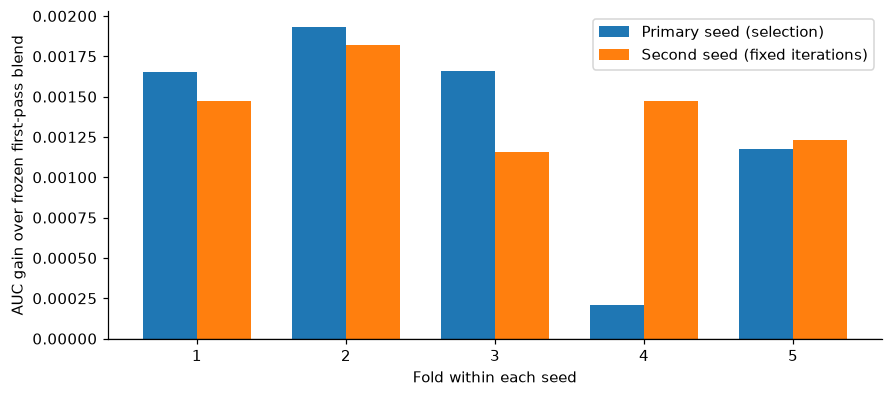

Final decision: selected after stability check


rule                               If the third model has nonpositive incremental...
prospective_guard                  No new-candidate second-seed fold result exist...
pair                               {'names': ['lgb_tune_15', 'r2_cat_term_proxies...
full_secondary_auc                                                          0.762876
pair_secondary_auc                                                          0.762863
third_model_secondary_increment                                             0.000013
pair_primary_gain                                                           0.001182
pair_secondary_gain                                                         0.001439
pair_secondary_fold_gain           [0.0013876388473670342, 0.0020459741215798077,...
pair_passes_original_gates                                                      True
simplified                                                                     False
weights_retuned                                                  

In [4]:
stability=r.read(ART/'stability_results.json')
display(pd.Series(stability))
g1=provisional['fold_gain'];g2=stability['fold_gain']
fig,ax=plt.subplots(figsize=(8,3.5),layout='constrained')
loc=np.arange(5);ax.bar(loc-.18,g1,.36,label='Primary seed (selection)');ax.bar(loc+.18,g2,.36,label='Second seed (fixed iterations)')
ax.axhline(0,color='black',linewidth=.8);ax.set(xticks=loc,xticklabels=np.arange(1,6),xlabel='Fold within each seed',ylabel='AUC gain over frozen first-pass blend')
ax.legend();plt.show()
print('Final decision:',selection['status'])
if (ART/'complexity_check_results.json').exists(): display(pd.Series(r.read(ART/'complexity_check_results.json')))

## Learning-curve evidence

The first fold of one new CV model is shown without selecting a particularly favorable fold. All available fold curves are retained. These curves explain stopping behavior; their validation labels contributed to model selection.

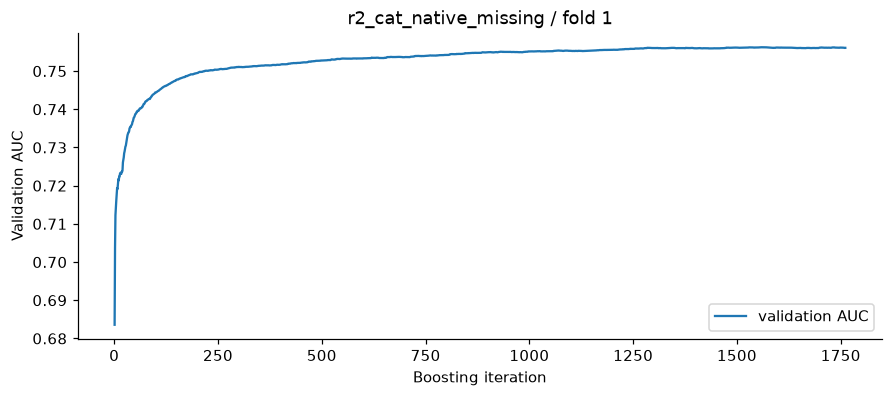

In [5]:
files=sorted((ART/'cv').glob('*/fold0_learning_curve.json'))
if files:
    file=files[0];curve=r.read(file)
    series=[]
    for dataset,metrics in curve.items():
        for metric,values in metrics.items():
            if metric.lower()=='auc': series.append((dataset,metric,values))
    fig,ax=plt.subplots(figsize=(8,3.5),layout='constrained')
    for dataset,metric,values in series: ax.plot(np.arange(1,len(values)+1),values,label=dataset+' '+metric)
    ax.set(xlabel='Boosting iteration',ylabel='Validation AUC',title=file.parent.name+' / fold 1')
    ax.legend();plt.show()

## Final saved-model bank and exact reproduction

All final weights and iteration counts are frozen before fitting on all labeled data. The first-pass final fold models can be reused without changes. New model families and any justified second fold seed are trained separately under `improvements/round2/models`.

Each test prediction averages the saved fold probabilities in a deterministic order, then applies the frozen model weights. The following cell reloads the actual models; it does not copy a cached prediction column.

In [6]:
final=r.read(ART/'final_results.json')
display(pd.Series(final));display(pd.DataFrame(final['models']))
from finalize import reproduce
path=reproduce()
display(pd.read_csv(path).head())
print('Expected SHA-256:',final['sha256'])

submission                                         output/submission_round2.csv
sha256                        ca654e22e1f0e4d807456e666d6fd9562d31979dc0f6ed...
rows                                                                      61500
probability_min                                                        0.002208
probability_max                                                        0.809835
probability_mean                                                       0.088424
models                        [{'name': 'lgb_tune_15', 'weight': 0.1875, 'se...
full_oof_auc                                                           0.764431
full_oof_average_precision                                             0.247857
full_oof_log_loss                                                      0.244405
full_oof_independent                                                      False
recommended_new_recipe                                                     True
two_seed_bagging                        

,name,weight,seeds
0,lgb_tune_15,0.1875,2
1,r2_cat_term_proxies,0.5625,2
2,r2_cat_proxies_native,0.2500,2


Byte-for-byte reproduction verified: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/output/submission_round2_reproduced.csv


,SK_ID_CURR,TARGET
0,171202,0.029203
1,171203,0.202430
2,171204,0.150990
3,171205,0.108660
4,171206,0.175309


Expected SHA-256: ca654e22e1f0e4d807456e666d6fd9562d31979dc0f6ed2195491e9a47da9546


### Which features did the final models use?

These are mean fold importances, with the complete tables retained as CSVs. CatBoost uses prediction-value-change importance; LightGBM and XGBoost use gain. Scales differ between algorithms and should not be compared directly. Correlated representations can share importance; the plots describe the fitted recipe, not causal financial effects.

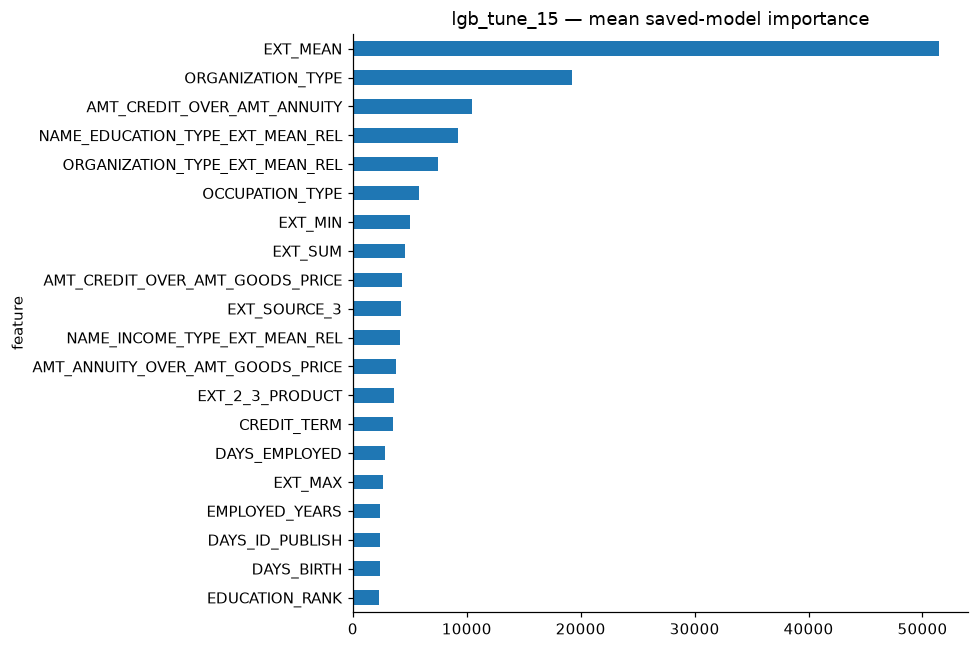

,mean_importance,fold_std
feature,,
EXT_MEAN,51422.575176,4890.814429
ORGANIZATION_TYPE,19230.015419,543.210229
AMT_CREDIT_OVER_AMT_ANNUITY,10433.054381,863.780916
NAME_EDUCATION_TYPE_EXT_MEAN_REL,9226.042411,3088.167387
ORGANIZATION_TYPE_EXT_MEAN_REL,7472.683852,1717.236062
OCCUPATION_TYPE,5772.799698,404.721229
EXT_MIN,4992.940394,515.750231
EXT_SUM,4569.189773,465.790639
AMT_CREDIT_OVER_AMT_GOODS_PRICE,4308.037999,473.109309


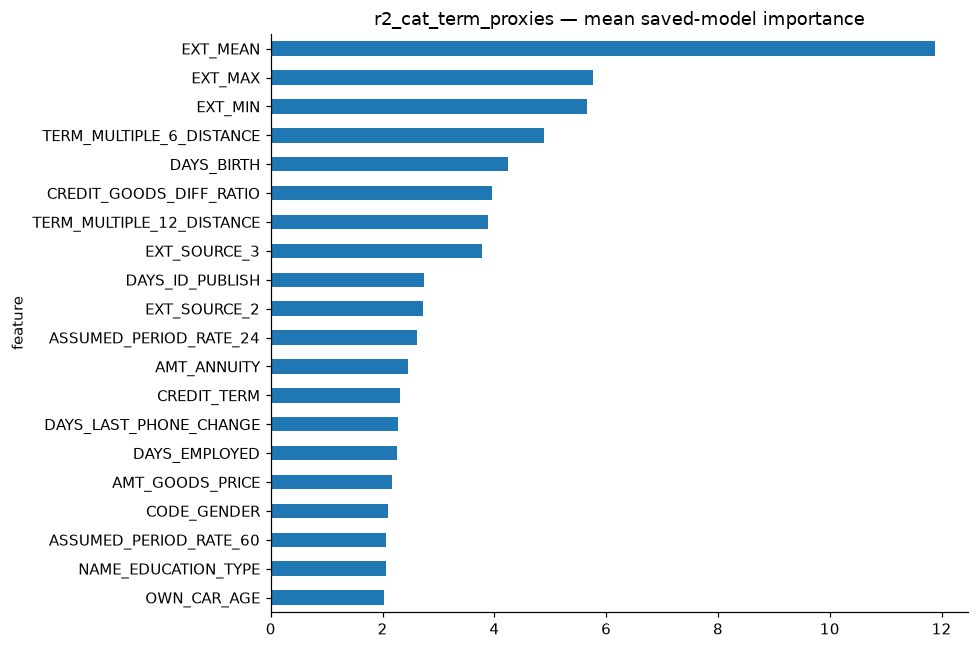

,mean_importance,fold_std
feature,,
EXT_MEAN,11.878451,1.553074
EXT_MAX,5.756121,0.937082
EXT_MIN,5.652789,0.745157
TERM_MULTIPLE_6_DISTANCE,4.890039,0.320588
DAYS_BIRTH,4.239420,0.221274
CREDIT_GOODS_DIFF_RATIO,3.961808,0.198227
TERM_MULTIPLE_12_DISTANCE,3.881911,0.214005
EXT_SOURCE_3,3.779042,0.282514
DAYS_ID_PUBLISH,2.731976,0.199889


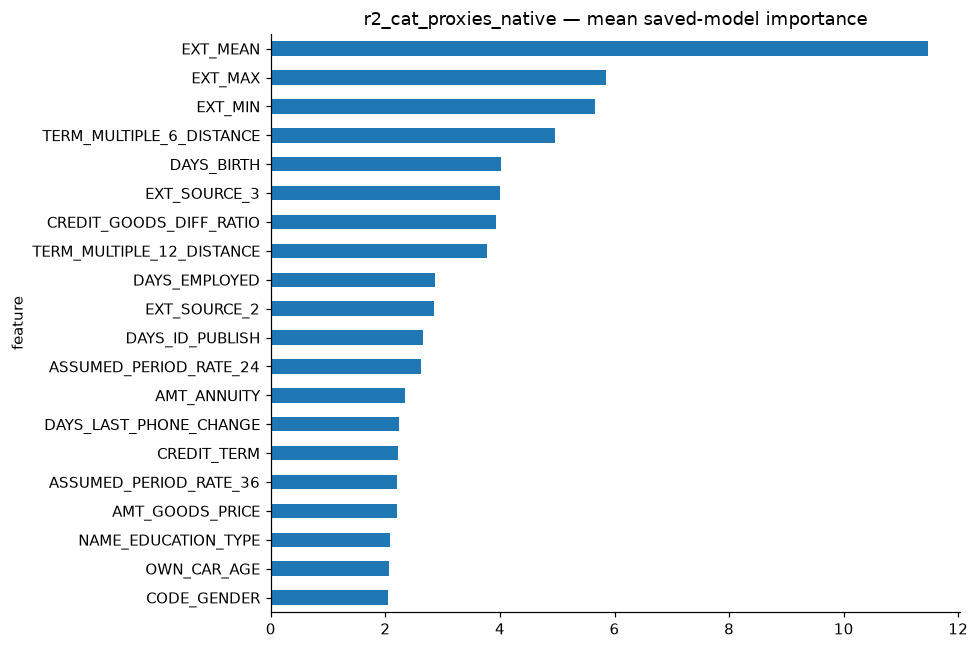

,mean_importance,fold_std
feature,,
EXT_MEAN,11.464089,0.805328
EXT_MAX,5.845476,0.693867
EXT_MIN,5.651095,0.647072
TERM_MULTIPLE_6_DISTANCE,4.961002,0.334263
DAYS_BIRTH,4.016191,0.267349
EXT_SOURCE_3,4.002359,0.275950
CREDIT_GOODS_DIFF_RATIO,3.929435,0.205194
TERM_MULTIPLE_12_DISTANCE,3.779120,0.283240
DAYS_EMPLOYED,2.858855,0.180056


In [7]:
for item in final['models']:
    file=ART/(item['name']+'_final_importance.csv')
    importance=pd.read_csv(file,index_col=0)
    importance.head(20).sort_values('mean_importance').mean_importance.plot.barh(figsize=(9,6),title=item['name']+' — mean saved-model importance')
    plt.tight_layout();plt.show()
    display(importance.head(20))

## Submission choice and remaining uncertainty

`output/submission_improved.csv` is the preserved file with the confirmed public score 0.7654.
`output/submission_round2.csv` is the new candidate, or an exact fallback copy if no improvement passed validation.
Read the recommendation in `final_results.json` and `IMPROVEMENT_REPORT.md` before uploading. The new public score is not known locally, and the competition's local README says the last submitted file determines the final entry.

The complete per-trial explanations, configurations, rejected ideas, runtime incidents and raw evidence are in `EXPERIMENT_LOG.md` and its machine-readable ledger. All prior notebooks remain unchanged.